# Raghavan et al. 2021 — Pancreatic Ductal Adenocarcinoma (Seq-Well)
## 01 · Preprocessing → Gate 1 (integration + continuity)

Malignant-only re-analysis. Every tunable choice is **derived from this dataset** (per-sample gap-finding threshold, Harmony θ from a mixing sweep, island removal, house orientation) and **shown in-notebook**, not inherited from the Puram2017 skeleton. Gate 1 is judged on the regenerated embedding with a per-neighbourhood metric (iLISI), not a single scalar.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>-1
name = os.path.basename(os.getcwd())                       # 'Raghavan2021_Pancreas-1'
name_data = name[:-2] if name.endswith('-1') else name     # raw folder has no -1 suffix
cat  = os.path.basename(os.path.dirname(os.getcwd()))       # 'Pancreas'
pth  = os.path.join(*([os.pardir]*4))                       # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name_data)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', 'Data_'+name_data)

dataset: Raghavan2021_Pancreas-1 | category: Pancreas | raw: Data_Raghavan2021_Pancreas


### Load malignant cells
Seq-Well UMI counts → loader `normalize_total` + `log1p`. Analyze **Malignant** cells only.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full load:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('metastatic site (source):', adata.obs['source'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Raghavan2021_Pancreas
Done.
full load: (24412, 16814)
malignant: (7904, 16814) | samples: 23 | patients: 23
metastatic site (source): {'Liver': 6778, 'Omentum': 931, 'Adrenal gland': 120, 'Lung': 46, 'Peritoneum': 29}
expression: X max 7.61 (log1p of normalize_total counts)


### Sample threshold — derived by gap-finding (C1/C2)
Sort per-sample malignant counts, find the largest multiplicative gap, set the threshold at the geometric mean across that gap. No inherited constant.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [1053  674  662  612  574  555  516  390  376  322  260  250  237  229
  208  197  164  159  143  129  120   45   29]
largest gap: 120 -> 45 (ratio 2.67)
derived threshold (geometric mean across the gap) = 73
kept 21/23 samples -> 7830 cells


### Genes, overdispersion, PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('cumulative variance: @20 %.3f  @30 %.3f  @40 %.3f' % (vr[:20].sum(), vr[:30].sum(), vr[:40].sum()))
print('n_pcs=20 chosen (Puram-40/Kuerten-20 scale; captures 43% variance on this 7.8k-cell Seq-Well set)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1497 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1497
cumulative variance: @20 0.428  @30 0.467  @40 0.491
n_pcs=20 chosen (Puram-40/Kuerten-20 scale; captures 43% variance on this 7.8k-cell Seq-Well set)


### Harmony integration on `sample` — θ from a mixing sweep (C1/C2)
Sweep integration strength; pick the θ where same-sample neighbour fraction plateaus (strongest integration without collapse).

In [6]:
def same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
NPCS = 20
base = same_sample_frac(adata.obsm['X_pca'][:,:NPCS])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = same_sample_frac(adata.obsm['X_pca_harmony'][:,:NPCS])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5; theta=10 is strongest without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

same-sample neighbour fraction | pre-Harmony 0.940 | sweep {2: 0.32, 5: 0.295, 10: 0.298}
selected theta = 10 (mixing plateaus by theta=5; theta=10 is strongest without collapse)


### Island removal — radius-graph connected components (C1/C2)

In [7]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands ->',
      int((lab==main).sum()), 'cells in one component')
adata = adata[lab==main].copy()

removed 0 cells in 0 detached islands -> 7830 cells in one component


### Sub-region biology BEFORE the Gate-1 GO (Kürten lobe-identity fork)
Cluster into lobes; test whether any lobe is a cycling compartment that confounds a module. Score the three developmental modules and check them against cell-cycle scores.

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())

lobe sizes: {'1': 5316, '0': 2514}
cycling fraction per lobe: {'0': 0.09, '1': 0.19}


In [9]:
# score developmental modules (union control pool) to test the proliferation confound
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
from scipy.stats import spearmanr
cyc_s = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s_s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
print('module vs cell-cycle (Spearman rho):')
for m in ['Gast','pSom','Crest']:
    r1,_ = spearmanr(cyc_s, adata.obs[m]); r2,_ = spearmanr(g1s_s, adata.obs[m])
    print(f'  {m}: vs g2m rho={r1:+.2f} | vs g1s rho={r2:+.2f}')
print('per-lobe module means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast','pSom','Crest']].mean().round(3).to_string())
print('-> modules only weakly tied to cell cycle (|rho|<=0.17; Gast mildly NEGATIVE), and per-lobe\n'
      '   module means are near-identical: the developmental axis is orthogonal to the proliferation\n'
      '   split -> keep the whole manifold (no scoping).')

module vs cell-cycle (Spearman rho):
  Gast: vs g2m rho=-0.15 | vs g1s rho=-0.17
  pSom: vs g2m rho=-0.04 | vs g1s rho=-0.07
  Crest: vs g2m rho=+0.08 | vs g1s rho=+0.11
per-lobe module means:
       Gast   pSom  Crest
lobe                     
0    -0.013  0.061 -0.020
1    -0.011  0.077 -0.025
-> modules only weakly tied to cell cycle (|rho|<=0.17; Gast mildly NEGATIVE), and per-lobe
   module means are near-identical: the developmental axis is orthogonal to the proliferation
   split -> keep the whole manifold (no scoping).


### Gate 1 — per-neighbourhood mixing (iLISI) on the regenerated embedding

In [10]:
def ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
n_samp = adata.obs['sample'].nunique()
il_pre  = np.median(ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal).')
print('GATE 1 = GO: samples intermix per-neighbourhood (iLISI ~7/21) on one continuous manifold.')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 7.07 of 21 samples
21 samples share one continuous manifold (one connected component after island removal).
GATE 1 = GO: samples intermix per-neighbourhood (iLISI ~7/21) on one continuous manifold.


### Save `processed.h5ad` + `samples.pdf`
House orientation: rigid rotation putting the principal axis horizontal, developmental origin on the left (shared by 02/03/04).

In [11]:
# house orientation (rigid rotation; distances preserved)
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
xyr = c @ Rm.T
dev = (adata.obs['Gast'] + adata.obs['pSom'] - adata.obs['Crest']).values  # developmental origin score
w = dev - dev.min() + 1e-9
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]   # origin pole -> left
adata.obsm['X_umap_lin'] = xyr
print('aspect (max/min std): %.2f | rigid rotation %+.1f deg; origin pole on left (X_umap_lin)'
      % (c.std(0).max()/c.std(0).min(), np.degrees(th)))

aspect (max/min std): 1.10 | rigid rotation -168.1 deg; origin pole on left (X_umap_lin)


In [12]:
# tidy obs dtypes then write
for cc in adata.obs.columns:
    col = adata.obs[cc]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cc] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7830, 16784)


saved samples.pdf | cells: 7830


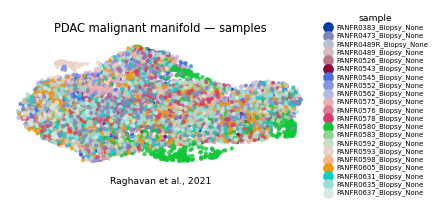

In [13]:
# samples.pdf — single sample-coloured manifold on the house orientation (Gate-1 evidence)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.22, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('PDAC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])